In [9]:
#Time Series Data Analysis & Preprocessing
# UCI HAR Dataset (Daily Activity Logger)

import pandas as pd
import numpy as np
import requests
import io
from zipfile import ZipFile
import matplotlib.pyplot as plt

# Step 1: Load the Dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00240/UCI%20HAR%20Dataset.zip"
response = requests.get(url)
zip_file = ZipFile(io.BytesIO(response.content))

# X_train = pd.read_csv(zip_file.open("UCI HAR Dataset/train/X_train.txt"), 
#                       delim_whitespace=True, header=None)
X_train = pd.read_csv(zip_file.open("UCI HAR Dataset/train/X_train.txt"),
                      sep='\s+', header=None)

y_train = pd.read_csv(zip_file.open("UCI HAR Dataset/train/y_train.txt"), 
                      header=None, names=["Activity"])

subject_train = pd.read_csv(zip_file.open("UCI HAR Dataset/train/subject_train.txt"), 
                            header=None, names=["Subject"])

train_data = pd.concat([subject_train, y_train, X_train], axis=1)

print("Dataset Loaded Successfully!")
train_data.head()


Dataset Loaded Successfully!


,Subject,Activity,0,1,2,3,4,5,6,7,...,551,552,553,554,555,556,557,558,559,560
0,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [10]:
# Step 2: Parse timestamps

train_data["Timestamp"] = pd.date_range(
    start="2025-12-01",
    periods=len(train_data),
    freq="20ms"  
)

cols = ["Timestamp"] + [col for col in train_data.columns if col != "Timestamp"]
train_data = train_data[cols]

train_data.head()

,Timestamp,Subject,Activity,0,1,2,3,4,5,6,...,551,552,553,554,555,556,557,558,559,560
0,2025-12-01 00:00:00.000,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,2025-12-01 00:00:00.020,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,2025-12-01 00:00:00.040,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,2025-12-01 00:00:00.060,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,2025-12-01 00:00:00.080,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [11]:
# Step 3: Sort by timestamp

train_data = train_data.sort_values(by="Timestamp").reset_index(drop=True)
train_data.head()

,Timestamp,Subject,Activity,0,1,2,3,4,5,6,...,551,552,553,554,555,556,557,558,559,560
0,2025-12-01 00:00:00.000,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,2025-12-01 00:00:00.020,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,2025-12-01 00:00:00.040,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,2025-12-01 00:00:00.060,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,2025-12-01 00:00:00.080,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


In [12]:
# Step 4: Handle missing values

missing_count = train_data.isnull().sum().sum()
print("Total missing values:", missing_count)

Total missing values: 0


In [13]:
# Step 5: Clean duplicates / rename columns

train_data = train_data.drop_duplicates()

train_data.rename(columns={
    "Subject": "SubjectID",
    "Activity": "ActivityLabel"
}, inplace=True)

train_data.head()


,Timestamp,SubjectID,ActivityLabel,0,1,2,3,4,5,6,...,551,552,553,554,555,556,557,558,559,560
0,2025-12-01 00:00:00.000,1,5,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,2025-12-01 00:00:00.020,1,5,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,2025-12-01 00:00:00.040,1,5,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,2025-12-01 00:00:00.060,1,5,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,2025-12-01 00:00:00.080,1,5,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


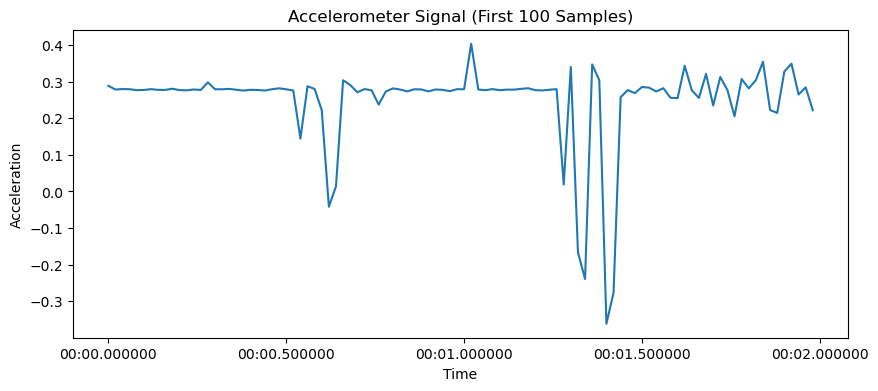

In [14]:
# Step 6: Simple Visualization

plt.figure(figsize=(10,4))
plt.plot(train_data["Timestamp"][:100], train_data[0][:100])
plt.title("Accelerometer Signal (First 100 Samples)")
plt.xlabel("Time")
plt.ylabel("Acceleration")
plt.show()


In [15]:
summary = {
    "Step": [
        "Parsed timestamps",
        "Sorted chronologically",
        "Handled missing values",
        "Cleaned dataset"
    ],
    "Why it's important": [
        "Allows time-based analysis & plotting",
        "Ensures correct time order for calculations",
        "Prevents errors in processing",
        "Keeps data consistent and readable"
    ]
}

pd.DataFrame(summary)


,Step,Why it's important
0,Parsed timestamps,Allows time-based analysis & plotting
1,Sorted chronologically,Ensures correct time order for calculations
2,Handled missing values,Prevents errors in processing
3,Cleaned dataset,Keeps data consistent and readable
